# P07 — Explainability dan interpretability pada prediksi Marshall

Notebook ini membaca `marshall_regression.csv` dari P06A Bab 6. Ia membandingkan penjelasan global, lokal, intrinsik dan surrogate; hasil menjelaskan perilaku model sintesis, bukan hukum material atau sebab-akibat.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_absolute_error
SEED=260616
candidates=[Path("praktikum/bab06/data_bab6/marshall_regression.csv"), Path("data_bab6/marshall_regression.csv"), Path("../../praktikum/bab06/data_bab6/marshall_regression.csv")]
DATA=next((p for p in candidates if p.exists()), candidates[0])
if not DATA.exists():
    try:
        from google.colab import files
        print("Unggah marshall_regression.csv dari P06A_generator_data_sintesis.ipynb")
        files.upload()
        DATA=Path("marshall_regression.csv")
    except ImportError as exc:
        raise FileNotFoundError("Jalankan P06A atau salin data_bab6/marshall_regression.csv ke folder kerja P07.") from exc
if not DATA.exists():
    raise FileNotFoundError("CSV tidak ditemukan. Jalankan generator Bab 6 atau unggah marshall_regression.csv.")
df=pd.read_csv(DATA)
features=["binder_pct","air_void_pct","vma_pct","aggregate_shape_index","gradation_index"]
target="stability_kN"
X=df[features]; y=df[target]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,random_state=SEED)
print("File:",DATA,"| data:",df.shape,"| fitur:",features)


File: praktikum/bab06/data_bab6/marshall_regression.csv | data: (800, 7) | fitur: ['binder_pct', 'air_void_pct', 'vma_pct', 'aggregate_shape_index', 'gradation_index']


## 1. Bangun satu model untuk diperiksa
Model Random Forest digunakan sebagai contoh perilaku model nonlinear. Skor di bawah hanya memastikan prediksi masuk akal untuk demonstrasi; tidak menilai kelayakan penggunaan rekayasa.

In [2]:
model=RandomForestRegressor(n_estimators=300,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
model.fit(X_train,y_train)
pred=model.predict(X_test)
print("R2 demo:",round(r2_score(y_test,pred),3),"MAE:",round(mean_absolute_error(y_test,pred),3),"kN")

R2 demo: 0.557 MAE: 1.796 kN


## 2. Kepentingan global melalui permutasi
Skor menunjukkan perubahan kinerja model ketika satu fitur diacak pada data uji. Ini mengukur ketergantungan prediktif model pada fitur dalam data ini. Fitur yang saling berkorelasi dapat saling menggantikan sehingga skor terbagi atau mengecil.

Mean permutation importance (kN, neg-MAE score): {'aggregate_shape_index': 0.042, 'gradation_index': 0.061, 'air_void_pct': 0.38, 'vma_pct': 0.583, 'binder_pct': 0.924}


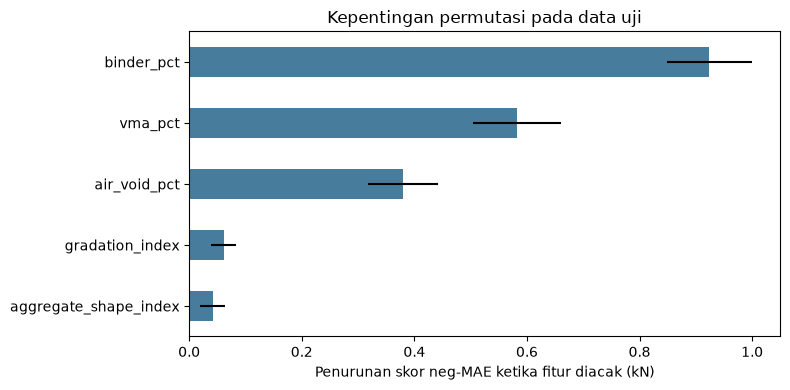

In [3]:
perm=permutation_importance(model,X_test,y_test,n_repeats=20,random_state=SEED,scoring="neg_mean_absolute_error")
imp=pd.Series(perm.importances_mean,index=features).sort_values()
print("Mean permutation importance (kN, neg-MAE score):",imp.round(3).to_dict())
ax=imp.plot.barh(xerr=pd.Series(perm.importances_std,index=features).loc[imp.index],figsize=(8,4),color="#477c9d")
ax.set_xlabel("Penurunan skor neg-MAE ketika fitur diacak (kN)"); ax.set_title("Kepentingan permutasi pada data uji"); plt.tight_layout()

## 3. PDP dan ICE
PDP merata-ratakan respons model saat satu fitur diubah; ICE menampilkan lintasan masing-masing pengamatan. Kurva adalah perilaku prediktif, bukan respons akibat intervensi fisik. Karena fitur saling berkorelasi dan dibangkitkan dalam rentang tertentu, jangan menafsirkan kurva di luar dukungan data.

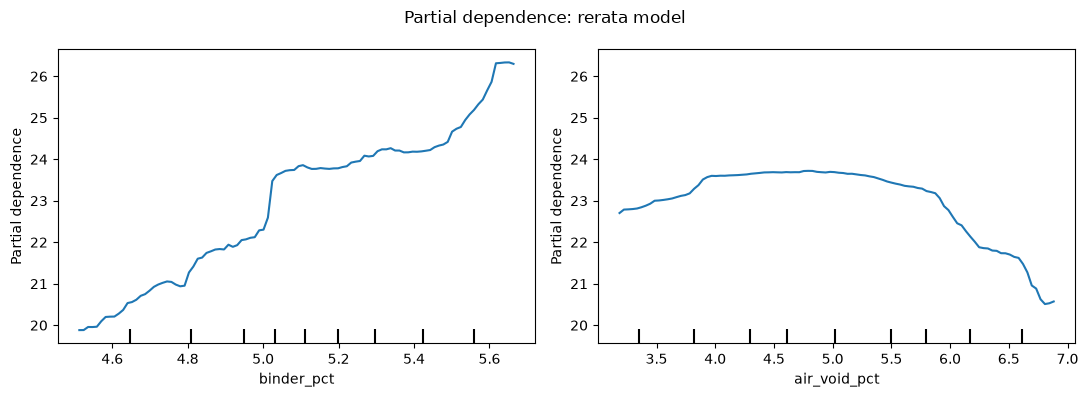

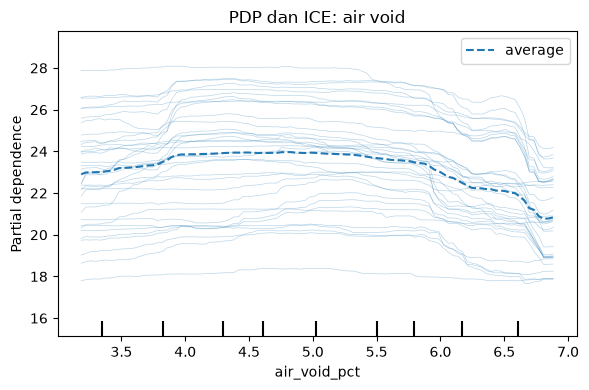

In [4]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
PartialDependenceDisplay.from_estimator(model,X_test,["binder_pct","air_void_pct"],kind="average",ax=ax)
fig.suptitle("Partial dependence: rerata model"); fig.tight_layout()
fig,ax=plt.subplots(figsize=(6,4))
PartialDependenceDisplay.from_estimator(model,X_test,["air_void_pct"],kind="both",subsample=35,random_state=SEED,ax=ax)
ax.set_title("PDP dan ICE: air void"); fig.tight_layout()

## 4. Penjelasan intrinsik: pohon dangkal
Pohon kecil lebih mudah dibaca tetapi mungkin kurang akurat dibanding ensemble. Batas kedalaman membuat contoh terlihat; bukan berarti pohon tersebut menangkap seluruh hubungan material.

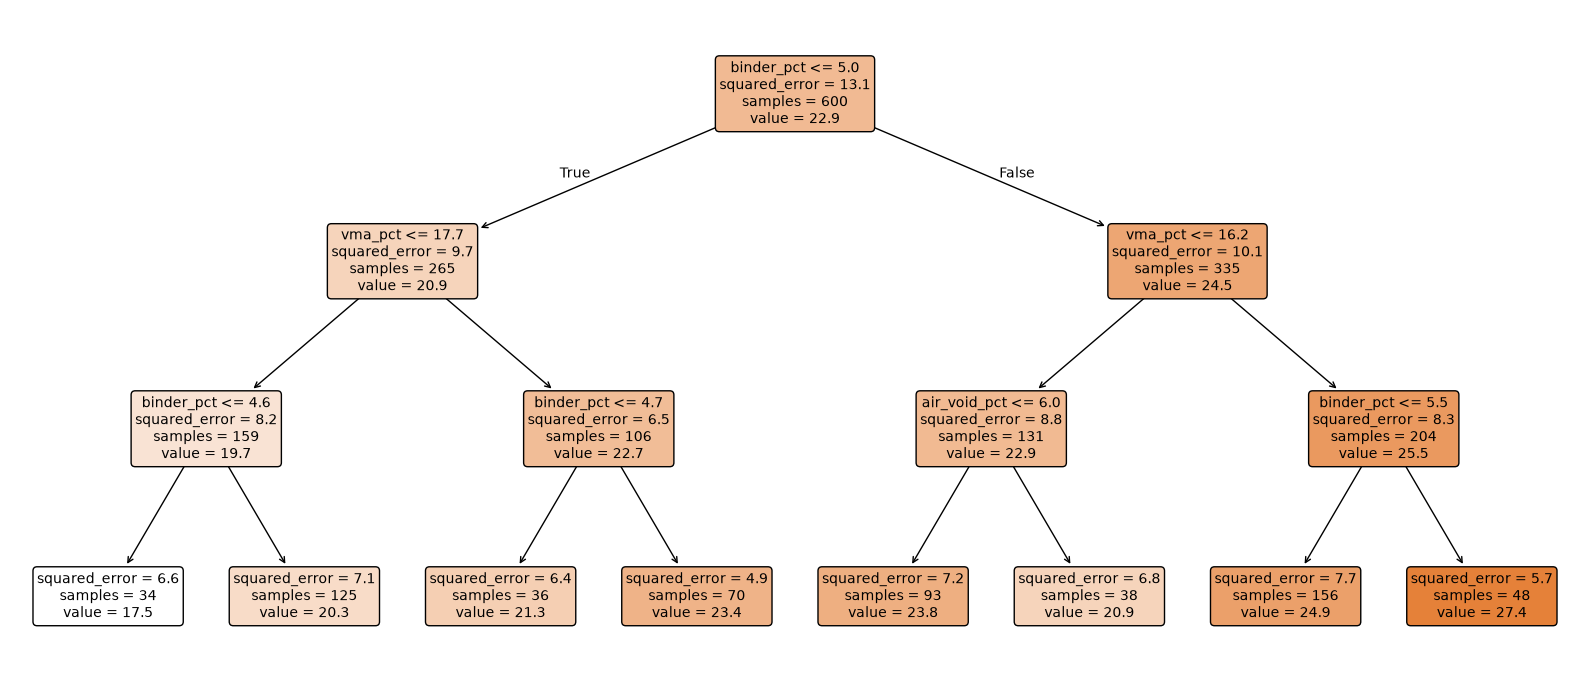

In [5]:
small_tree=DecisionTreeRegressor(max_depth=3,min_samples_leaf=25,random_state=SEED).fit(X_train,y_train)
fig,ax=plt.subplots(figsize=(16,7))
plot_tree(small_tree,feature_names=features,filled=True,rounded=True,precision=1,ax=ax)
plt.tight_layout()

## 5. Pohon surrogate untuk meniru Random Forest
Surrogate dilatih untuk meniru prediksi Random Forest, bukan nilai aktual. Fidelity di bawah membandingkan dua keluaran pada data uji; ia bukan ukuran akurasi terhadap stabilitas laboratorium.


Fidelity R2 vs Random Forest: 0.616
Fidelity MAE (kN): 1.103


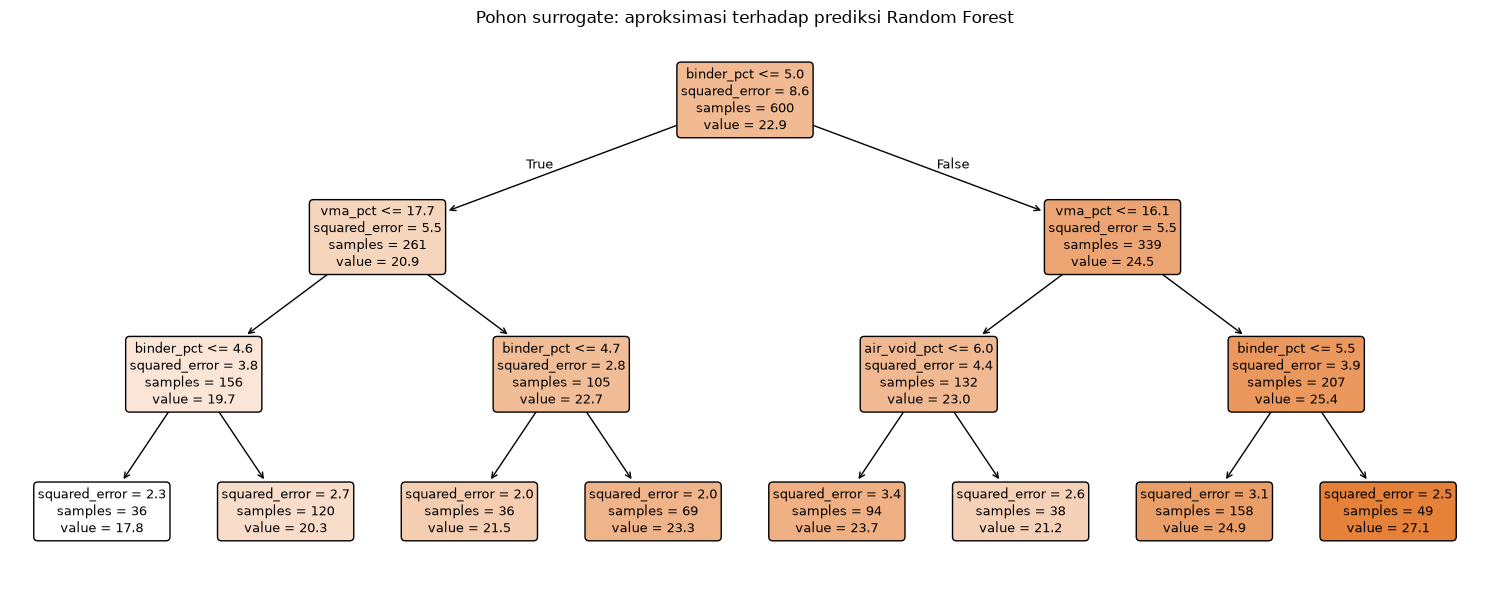

In [6]:
forest_train_pred=model.predict(X_train)
surrogate=DecisionTreeRegressor(max_depth=3,min_samples_leaf=25,random_state=SEED)
surrogate.fit(X_train,forest_train_pred)
surrogate_test_pred=surrogate.predict(X_test)
print("Fidelity R2 vs Random Forest:",round(r2_score(pred,surrogate_test_pred),3))
print("Fidelity MAE (kN):",round(mean_absolute_error(pred,surrogate_test_pred),3))
fig,ax=plt.subplots(figsize=(15,6))
plot_tree(surrogate,feature_names=features,filled=True,rounded=True,precision=1,ax=ax)
ax.set_title("Pohon surrogate: aproksimasi terhadap prediksi Random Forest")
plt.tight_layout()


## 6. Satu prediksi lokal
Bandingkan kontribusi fitur untuk satu spesimen dengan prediksi dan rentang data. Metode perturbasi sederhana berikut hanya diagnostik sensitivitas lokal; bukan SHAP atau LIME dan tidak punya jaminan dekomposisi kontribusi.

In [7]:
i=0; x0=X_test.iloc[[i]]; yhat=float(model.predict(x0)[0])
rows=[]
for f in features:
    lo,hi=X_train[f].quantile([.1,.9])
    vals=np.linspace(lo,hi,31); batch=pd.concat([x0]*len(vals),ignore_index=True); batch[f]=vals
    yh=model.predict(batch)
    rows.append((f,float(x0.iloc[0][f]),float(yh.min()),float(yh.max())))
local=pd.DataFrame(rows,columns=["fitur","nilai pengamatan","rentang prediksi saat fitur diubah","batas atas"] )
print("Prediksi",round(yhat,2),"kN; aktual",round(float(y_test.iloc[i]),2),"kN")
local

Prediksi 20.45 kN; aktual 17.18 kN


,fitur,nilai pengamatan,rentang prediksi saat fitur diubah,batas atas
0,binder_pct,4.525604,20.401185,26.988296
1,air_void_pct,6.593444,20.440196,22.119077
2,vma_pct,20.258025,17.863716,20.411369
3,aggregate_shape_index,0.367640,20.258473,22.086852
4,gradation_index,3.190103,20.373484,20.538009


## 7. Opsional: SHAP dan LIME di Google Colab
Instalasi bersifat opsional. SHAP dan LIME menjelaskan prediksi relatif pada definisi baseline/sampling masing-masing; hasil dapat berbeda dan tetap bukan bukti sebab-akibat. Jalankan bagian ini bila pustaka tersedia.

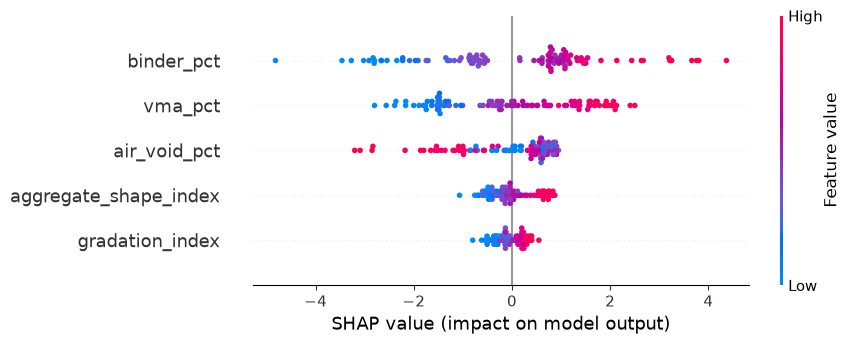

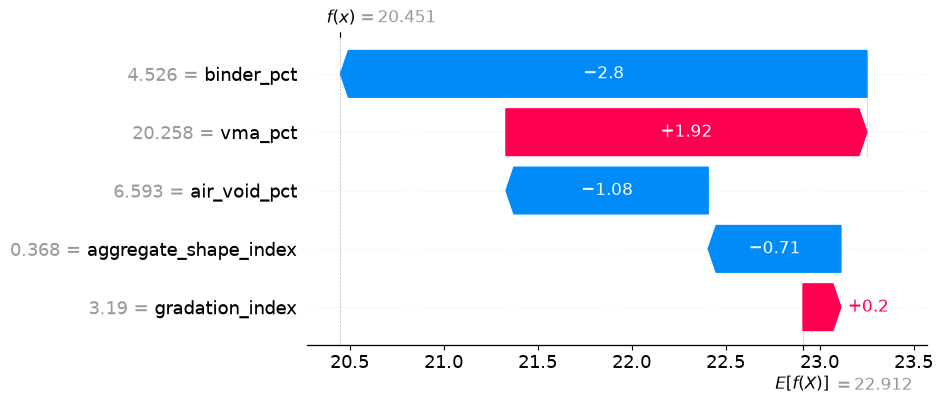

[('binder_pct <= 4.79', -3.5403927924895853), ('vma_pct > 18.91', 2.1799622421168623), ('air_void_pct > 5.87', -1.5504422650623877), ('aggregate_shape_index <= 0.46', -0.7132639459975582), ('gradation_index > 3.14', 0.4751820934968334)]


In [8]:
# Di Colab, bila diperlukan: %pip -q install shap lime
import importlib.util
if importlib.util.find_spec("shap"):
    import shap
    explainer=shap.TreeExplainer(model)
    sv=explainer(X_test.iloc[:100])
    shap.plots.beeswarm(sv)
    shap.plots.waterfall(sv[0])
else:
    print("SHAP belum terpasang; lewati atau instal shap di Colab.")
if importlib.util.find_spec("lime"):
    from lime.lime_tabular import LimeTabularExplainer
    lx=LimeTabularExplainer(X_train.to_numpy(),feature_names=features,mode="regression",random_state=SEED)
    explanation=lx.explain_instance(X_test.iloc[0].to_numpy(),model.predict,num_features=len(features))
    print(explanation.as_list())
else:
    print("LIME belum terpasang; lewati atau instal lime di Colab.")

## Refleksi tingkat Magister
1. Apakah peringkat permutasi selaras dengan pengetahuan campuran aspal? Jika tidak, hipotesis diagnostik apa yang perlu diperiksa?
2. Apakah PDP menghasilkan kombinasi fitur yang realistis? Tunjukkan batas dukungan data.
3. Apakah penjelasan global cukup untuk meninjau satu prediksi yang berisiko?
4. Apa perbedaan pernyataan “model bergantung pada fitur” dan “fitur menyebabkan respons”?
5. Jika model dipakai pada batch, sumber data, atau rentang komposisi berbeda, pemeriksaan apa yang diperlukan?

**Batas:** hasil hanya menggambarkan model terlatih pada generator sintesis Bab 6. Tidak menjadi rekomendasi komposisi, persamaan desain, atau inferensi kausal.